<a href="https://colab.research.google.com/github/SinhaPushkar047/Langgraph/blob/main/X_JokePost_generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [202]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal,Annotated
from pydantic import BaseModel,Field
import operator

In [203]:
from google.colab import userdata
groq_api=userdata.get('GROQ_API_KEY')

In [204]:
generation=ChatGroq(
    model='openai/gpt-oss-120b',
    api_key=groq_api
)

In [205]:
evaluation=ChatGroq(
    model='openai/gpt-oss-120b',
    api_key=groq_api
)

In [206]:
optmization=ChatGroq(
    model='openai/gpt-oss-120b',
    api_key=groq_api
)

In [207]:
class Struc_Eval(BaseModel):
  evaluation: Literal['approved','need_improvement']=Field(description='On the basis of evaluation give the desired output')

  feedback: str=Field(description='generate a small 100 word feedback about the joke')

In [208]:
struc_eval=evaluation.with_structured_output(Struc_Eval,method='json_schema')

In [209]:
class x_post(TypedDict):
  title:str
  tweet:str
  evaluation: Literal['approved','need_improvement']
  feedback: str
  curr_iter:int
  max_iter: int

  tweet_history= Annotated[list[str],operator.add]
  feedback_history=Annotated[list[str],operator.add]

In [210]:
def generate(state:x_post)->x_post:
  prompt = f"""
Write an original, funny, shareable X post about: {state['title']}.

Requirements:
- Create a joke from scratch; do not ask the user for a joke.
- Include a clear setup and punchline.
- Use a relatable comparison or unexpected twist.
- Keep it concise and under 280 characters.
- Return only the tweet text.
"""
  joke=generation.invoke(prompt).content

  return {'tweet':joke, 'tweet_history':[joke],'curr_iter':state['curr_iter']+1}

In [211]:
def evaluate(state:x_post)->x_post:
  prompt=f'''
  evaluate the joke on the basis of originality,humorous,virality and the format of joke

  this are the criteria for evaluation of joke on being approved:

  Originality: joke should be original not being copied from other jokes on internet or similar to it

  humorous: joke should be highly interesting and engaging

  virality: joke should reach to a major audience and get viral on X

  and most important joke should be inside 250 words

  if the above criteria is not fulfilled then reject the joke

  output should be in the structured format:
  evaluation: whether approved or need improvement
  feedback: generate small 100 word feedback about the joke

  joke->{state['tweet']}
  '''

  eval=struc_eval.invoke(prompt)

  return {'evaluation':eval.evaluation, 'feedback':eval.feedback, 'feedback_history':[eval.feedback]}

In [212]:
def optimized(state:x_post)->x_post:

  prompt=f"""
  Optimise the given joke on the basis of virality,humorous and feedback given
  joke-> {state['tweet']} \n feedback->{state['feedback']}
  """

  opt=optmization.invoke(prompt).content

  return {'tweet':opt,'curr_iter':state['curr_iter']+1}


In [213]:
def iteration(state:x_post)-> Literal['approved','need_evaluation']:
  if state['evaluation']=='approved' and state['curr_iter']<=state['max_iter']:
    return 'approved'
  elif state['evaluation']=='need_improvement' and state['curr_iter']<=state['max_iter']:
    return 'need_improvement'
  else:
    return 'approved'

In [214]:
graph=StateGraph(x_post)

graph.add_node('generate',generate)
graph.add_node('evaluate',evaluate)
graph.add_node('optimized',optimized)

graph.add_edge(START,'generate')
graph.add_edge('generate','evaluate')
graph.add_conditional_edges('evaluate',iteration,{'approved':END,'need_improvement':'optimized'})
graph.add_edge('optimized','evaluate')

workflow=graph.compile()

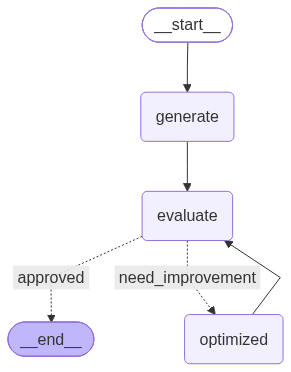

In [215]:
workflow

In [216]:
initial_state = {
    "title": "Samsung vs Apple",
    "curr_iter": 0,
    "max_iter": 5
}
result = workflow.invoke(initial_state)

In [217]:
result

{'title': 'Samsung vs Apple',
 'tweet': '**Optimised joke**\n\n> **Samsung:** “I can fold into a wallet.” 📱💸  \n> **Apple:** “I can fold your wallet *into* my price.” 🍎💰  \n> **Consumer:** “I’m just here for the charger that finally gets any use.” 🔌😅  \n\n**Why it’s more viral‑ready**\n\n- **Fresh angle:** Turns the usual “foldable vs pricey” rivalry into a three‑part exchange that ends on an unexpected, relatable gripe (the ever‑neglected charger).  \n- **Word‑play punch:** “Fold your wallet into my price” is kept, but the twist “I’m just here for the charger” flips the focus from money to a universal tech pain point, making the punchline sharper.  \n- **Social‑media friendly:** Short lines, emojis, and a hashtag‑ready vibe (e.g., #TechWars, #FoldableFiasco) boost shareability on X/Twitter.  \n- **Memetic potential:** The “consumer runs away” is replaced with a self‑deprecating “I’m just here for the charger,” a line that’s easy to meme‑ify or GIF‑ify.  \n\nFeel free to add a trailing